# Trámites administrativos y empresas de alto crecimiento

In [ ]:
# Parámetros de la gráfica
SLUG = "economia"  # carpeta en research/temas/
GRAFICA_ID = "carga-administrativa-empresas-alto-crecimiento"  # id de la gráfica (kebab-case) = nombre del notebook
TITULO = "Trámites administrativos y empresas de alto crecimiento"  # `titulo` de la gráfica en config.json
DESDE = 1976  # primer año candidato (METODOLOGIA §2.3)
UNIVERSO = "ocde"  # ocde | ue27: todos sus países con dato en los dos ejes (METODOLOGIA §2.6)
EJE_X = {"titulo": "Carga administrativa y regulatoria", "unidad": "índice de 0 (menor) a 6"}
EJE_Y = {"titulo": "Empresas de alto crecimiento", "unidad": "% de las empresas con 10 o más asalariados"}
ANIOS = None  # (desde, hasta) si el config fija una ventana; None = último año común de cada país
CSV_FORMATO = "es"  # CSV: "es" (separador ; y coma decimal, Excel en español) o "int" (, y punto)
CSV_DECIMALES = 2  # decimales del CSV (el JSON guarda el valor completo)
DIR_SALIDA = None  # solo tests; None = temas/<SLUG>/data/

## 1. Contexto

Cada punto es un país de la OCDE con dato en los dos ejes.

- **Eje horizontal:** el indicador de la OCDE de **carga administrativa y regulatoria** (`ADREG_BURDEN`, de la base de datos de regulación de los mercados de productos), de 0 (menor carga) a 6: recoge los requisitos administrativos para crear y gestionar empresas (licencias, permisos, ventanilla única), cuánto comunica y simplifica el gobierno esas cargas y su coste para los emprendedores.
- **Eje vertical:** el porcentaje de **empresas de alto crecimiento**: empresas con al menos 10 asalariados que aumentan su plantilla más de un 10 % al año durante tres años seguidos, sobre el total de empresas con al menos 10 asalariados.

**Para qué sirve.** Es el argumento de quienes proponen simplificar los trámites: que una carga administrativa alta frena el crecimiento de las empresas. Quienes defienden esos requisitos sostienen que protegen a consumidores, trabajadores o el medio ambiente. Se usan las empresas de alto crecimiento y no la natalidad de empresas porque la natalidad cuenta sobre todo empresas muy pequeñas sin asalariados, mientras que el debate de los trámites trata de que las empresas crezcan. **La relación entre dos indicadores no muestra que uno cause el otro**: no se dibuja línea de tendencia ni se calcula la correlación.

**Limitaciones.**
- El indicador mide la normativa y los procedimientos, no el tiempo ni el coste reales de cada trámite, y la OCDE lo publica solo en las ediciones de 2018 y 2023.
- Las empresas de alto crecimiento miden el crecimiento del empleo, no el de las ventas, y solo se publican para parte de los países de la OCDE y con años distintos; cada punto usa el último año en que el país tiene dato en los dos ejes.
- La carga administrativa no recoge los trámites de las comunidades autónomas, ayuntamientos o estados federados que no estén en la información nacional que la OCDE recopila.

## 2. Descarga

- **OCDE, regulación de los mercados de productos (PMR)** (`OECD.ECO.GCRD,DSD_PMR@DF_PMR`, versión 1.3): carga administrativa y regulatoria (`ADREG_BURDEN`), escala de 0 a 6, ediciones de 2018 y 2023. También el subindicador de requisitos administrativos para sociedades de responsabilidad limitada y empresas individuales (`ADBURDEN`), solo para contraste en las notas.
- **OCDE, demografía empresarial** (`OECD.SDD.TPS,DSD_SDBSBD_ISIC4@DF_BD_EMP_HG`, versión 1.0): empresas de alto crecimiento (`HGE10`, `PT_ENT10`, `S_GE10`) de la actividad `BTNXK`.
- **Contrastes para las notas:** España en Eurostat (`bd_hgnace_r`), qué publica la OCDE de Canadá y la tasa de natalidad de empresas con asalariados.

In [ ]:
import sys
from pathlib import Path

# Raíz del proyecto (la carpeta con global.json y lib/), buscando hacia arriba desde el directorio de ejecución
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "global.json").exists()), None)
if RAIZ is None:
    raise FileNotFoundError(
        "No se encuentra global.json. Abre el notebook desde su carpeta (temas/<tema>/notebooks/) "
        "dentro del repositorio completo; consulta el README para instalar el entorno."
    )
sys.path.insert(0, str(RAIZ))

import pandas as pd

from lib import estilos
from lib.paises import paises_de
from lib.writer import construir_dispersion_data, write_dispersion_data

PAISES = paises_de(UNIVERSO)

from datetime import date

from lib import eurostat, oecd
from lib.paises import nombre_punto
from lib.tipos import FuenteMeta

AREAS = {c: c for c in PAISES}  # todos los países del universo, con su código como clave de serie
HOY = date.today().isoformat()

# Empresas de alto crecimiento (demografía empresarial de la OCDE)
DATAFLOW_HG = "OECD.SDD.TPS,DSD_SDBSBD_ISIC4@DF_BD_EMP_HG,1.0"
# Dimensiones: frecuencia . país . medida (empresas) . actividad . tamaño (10 o más asalariados) . edad (todas)
#              . tipo (empresas con asalariados) . fase (crecimiento del empleo de más del 10 % anual) . unidad
ACTIVIDAD = "BTNXK"  # economía empresarial (secciones B a N de la CIIU/NACE) salvo actividades financieras y de seguros
CLAVE_HG = "A.{AREA}." + f"ENT.{ACTIVIDAD}.S_GE10._T.ENT_EMP.HGE10.PT_ENT10"
# Tasa de natalidad de las empresas con asalariados (solo notas)
DATAFLOW_NAT = "OECD.SDD.TPS,DSD_SDBSBD_ISIC4@DF_BD_EMP_B_D,1.0"
CLAVE_NAT = "A.{AREA}." + f"ENT.{ACTIVIDAD}._T.Y_LT1.ENT_EMP.B.PT_ENT_EM"


def descargar_hg():
    return oecd.get(DATAFLOW_HG, CLAVE_HG, areas=AREAS, desde=DESDE)


def otras_definiciones_hg(area):
    """Qué publica la OCDE de empresas de alto crecimiento para un país sin la definición de la gráfica.

    Con reintentos (`pedir`) y sin tragarse errores: si la consulta falla, el notebook falla en vez
    de escribir unas notas distintas.
    """
    import io

    import requests

    from lib._http import pedir

    r = pedir(
        requests.Session(), f"{oecd.BASE}/{DATAFLOW_HG}/A.{area}.ENT.......", None,
        error_cls=oecd.OecdError, etiqueta=f"empresas de alto crecimiento de {area}",
        mensaje=lambda r: r.text[:200], headers=oecd.CABECERA_CSV,
    )
    return pd.read_csv(io.StringIO(r.text), dtype=str)


def descargar_hg_eurostat():
    """Contraste de España con Eurostat (bd_hgnace_r)."""
    return eurostat.get(
        "bd_hgnace_r", {"freq": "A", "indic_sbs": "ENT_HGRWR_PC", "nace_r2": "B-S_X_O_S94"},
        geos={"ES": "ESP"}, desde=DESDE,
    )


def descargar_natalidad():
    return oecd.get(DATAFLOW_NAT, CLAVE_NAT, areas={"ESP": "ESP"}, desde=DESDE)[0]

DATAFLOW_PMR = "OECD.ECO.GCRD,DSD_PMR@DF_PMR,1.3"
# Dimensiones: país . medida . frecuencia (anual; las ediciones son 2018 y 2023)
CLAVE_PMR = "{AREA}.ADREG_BURDEN.A"
CLAVE_PMR_ADM = "{AREA}.ADBURDEN.A"

x, _ = oecd.get(DATAFLOW_PMR, CLAVE_PMR, areas=AREAS, desde=DESDE)
x_adm, _ = oecd.get(DATAFLOW_PMR, CLAVE_PMR_ADM, areas=AREAS, desde=DESDE)
y, _ = descargar_hg()
try:
    media_y, _ = oecd.get(DATAFLOW_HG, CLAVE_HG, areas={"OECD": "OECD", "EU27_2020": "EU27_2020"}, desde=DESDE)
except oecd.OecdError as e:
    assert "NoRecordsFound" in str(e), f"error distinto de «sin datos»: {e}"
    media_y = pd.DataFrame(columns=["serie", "periodo", "valor"])
hg_eurostat, _ = descargar_hg_eurostat()
natalidad_todos, _ = oecd.get(DATAFLOW_NAT, CLAVE_NAT, areas=AREAS, desde=DESDE)
natalidad = natalidad_todos[natalidad_todos["serie"] == "ESP"]
otras_can = otras_definiciones_hg("CAN")
print("Ediciones del PMR:", sorted(x["periodo"].unique()), "· países con PMR:", x["serie"].nunique(), "· con empresas de alto crecimiento:", y["serie"].nunique())

## 3. Transformación

1. Los dos ejes se usan tal como los publica la OCDE, sin transformar. El indicador de carga administrativa solo existe en las ediciones de 2018 y 2023 (y las empresas de alto crecimiento, en los años recientes), así que cada punto usa el último año en que el país tiene dato en los dos ejes.
2. **Elección del indicador:** se usa `ADREG_BURDEN` (carga administrativa y regulatoria completa) y no `ADBURDEN` (solo los requisitos de las sociedades de responsabilidad limitada y las empresas individuales) porque el debate de los trámites incluye las licencias y la simplificación de las cargas, no solo los requisitos para constituir la empresa. El valor de `ADBURDEN` de España queda en las notas.
3. **Sin puntos de medias:** la OCDE no publica las empresas de alto crecimiento para su media ni para la UE-27 (se comprueba en la descarga).
4. Para las notas: la relación con la tasa de natalidad de las empresas con asalariados (posición de España entre los países con dato).

In [ ]:
def unir(xs):
    xs = [str(x) for x in xs]
    return xs[0] if len(xs) == 1 else f"{', '.join(xs[:-1])} y {xs[-1]}"


def es(v, d=1):
    return estilos.formato_es(v, d)


def notas_hg(y, hg_eurostat, natalidad, otras_can):
    """Notas comunes del eje de las empresas de alto crecimiento."""
    _, flujo, version = DATAFLOW_HG.split(",")
    notas = [
        f"Empresas de alto crecimiento: OCDE, demografía empresarial ({flujo}, versión {version}): empresas con al "
        "menos 10 asalariados al inicio del periodo cuyo número de asalariados crece de media más de un 10 % al año "
        "durante tres años, en porcentaje de las empresas con al menos 10 asalariados (HGE10, PT_ENT10, S_GE10).",
        f"Actividad: economía empresarial salvo actividades financieras y de seguros ({ACTIVIDAD}, secciones B a N "
        "salvo K), el agregado de actividad con más países de la OCDE en esta definición.",
        "Mide el crecimiento del empleo, no el de la facturación, y no cuenta las empresas sin asalariados ni las "
        "que no crecen, a diferencia de la tasa de natalidad de empresas.",
    ]
    can = otras_can
    if len(can) and "HGE10" not in set(can["BUSINESS_STAGE"]):
        etapas = sorted(set(can["BUSINESS_STAGE"]) & {"HGE20", "HGT20", "HGE10T20"})
        notas.append(
            "Canadá no aparece: la OCDE solo publica sus empresas de alto crecimiento con otra definición "
            f"({unir(etapas)}: crecimiento de más del 20 % anual), sin la del 10 % de esta gráfica."
        )
    esp = y[y["serie"] == "ESP"].set_index("periodo")["valor"]
    eu = hg_eurostat.set_index("periodo")["valor"]
    comunes = sorted(set(esp.index) & set(eu.index))
    if comunes:
        a = comunes[-1]
        notas.append(
            f"España en Eurostat (bd_hgnace_r, industria, construcción y servicios salvo administración pública y "
            f"asociaciones, B-S_X_O_S94): {es(eu[a], 2)} % en {a}, frente al {es(esp[a], 2)} % de la OCDE ({ACTIVIDAD}); "
            "las dos fuentes no cubren las mismas actividades."
        )
    if len(natalidad):
        n = natalidad.sort_values("periodo").iloc[-1]
        notas.append(
            f"Tasa de natalidad de las empresas con asalariados de España (OCDE, {DATAFLOW_NAT.split(',')[1]}, "
            f"{ACTIVIDAD}): {es(n['valor'])} % de las empresas activas en {int(n['periodo'])}. No se usa en la gráfica: "
            "cuenta todas las empresas nuevas, también las pequeñas que no crecen."
        )
    return notas


assert media_y.empty, f"La OCDE publica las empresas de alto crecimiento de {sorted(media_y['serie'].unique())}: revisar si se añade el punto"
_, FLUJO_PMR, VERSION_PMR = DATAFLOW_PMR.split(",")
fuentes = [
    FuenteMeta("eje_x", oecd.ORGANISMO, f"{FLUJO_PMR} (Regulación de los mercados de productos, versión {VERSION_PMR}): ADREG_BURDEN", oecd.URL_EXPLORER, HOY),
    FuenteMeta("eje_y", oecd.ORGANISMO, f"{DATAFLOW_HG.split(',')[1]}: HGE10, PT_ENT10, S_GE10, {ACTIVIDAD}", oecd.URL_EXPLORER, HOY),
]
puntos = construir_dispersion_data(
    x, y, fuentes, id=GRAFICA_ID, universo=UNIVERSO, eje_x=EJE_X, eje_y=EJE_Y, notas=[],
    generado_por="", desde=DESDE, anios=ANIOS,
)["puntos"]
a_esp = next(p["anio"] for p in puntos if p["codigo"] == "ESP")
adm_esp = x_adm[(x_adm["serie"] == "ESP") & (x_adm["periodo"] == a_esp)]["valor"]

# Posición de España en la natalidad de las empresas con asalariados, en el año de cada punto
nat = natalidad_todos.set_index(["serie", "periodo"])["valor"]
pares = [(p["codigo"], nat.get((p["codigo"], p["anio"]))) for p in puntos]
pares = [(c, v) for c, v in pares if v is not None]
nat_esp = nat.get(("ESP", a_esp))

NOTAS = [
    f"Carga administrativa y regulatoria: OCDE, regulación de los mercados de productos ({FLUJO_PMR}, versión {VERSION_PMR}): "
    "indicador ADREG_BURDEN, escala de 0 (menor carga) a 6, ediciones de 2018 y 2023. Mide la normativa y los "
    "procedimientos, no el tiempo ni el coste reales de cada trámite.",
    "Se usa el indicador completo y no el subindicador ADBURDEN, que solo recoge los requisitos administrativos para "
    "constituir sociedades de responsabilidad limitada y empresas individuales.",
]
if len(adm_esp):
    NOTAS.append(f"ADBURDEN de España en {a_esp}: {es(adm_esp.iloc[0], 2)} (escala de 0 a 6).")
ediciones = sorted({p["anio"] for p in puntos})
ultima_edicion = int(x["periodo"].max())
if ultima_edicion not in ediciones:
    NOTAS.append(
        f"Los puntos usan la edición de {unir(ediciones)} del indicador de carga administrativa: las empresas de alto "
        f"crecimiento de la OCDE solo llegan hasta {int(y['periodo'].max())}, así que la edición de {ultima_edicion} no "
        "tiene ningún país con dato en los dos ejes."
    )
NOTAS.append("Sin punto de la media OCDE ni de la UE-27: la OCDE no publica las empresas de alto crecimiento para esos agregados.")
NOTAS += notas_hg(y, hg_eurostat, natalidad, otras_can)
if nat_esp is not None and pares:
    puesto = 1 + sum(1 for _, v in pares if v > nat_esp)
    NOTAS.append(
        f"Con la tasa de natalidad de las empresas con asalariados en lugar de las de alto crecimiento (OCDE, "
        f"{DATAFLOW_NAT.split(',')[1]}, {ACTIVIDAD}), España ({es(nat_esp)} % en {a_esp}) ocupa el puesto {puesto} de "
        f"{len(pares)} países con dato en el año de cada punto (de más a menos natalidad)."
    )

## 4. Visualización

Un punto por país, sin línea de tendencia ni correlación (METODOLOGIA §2.6).

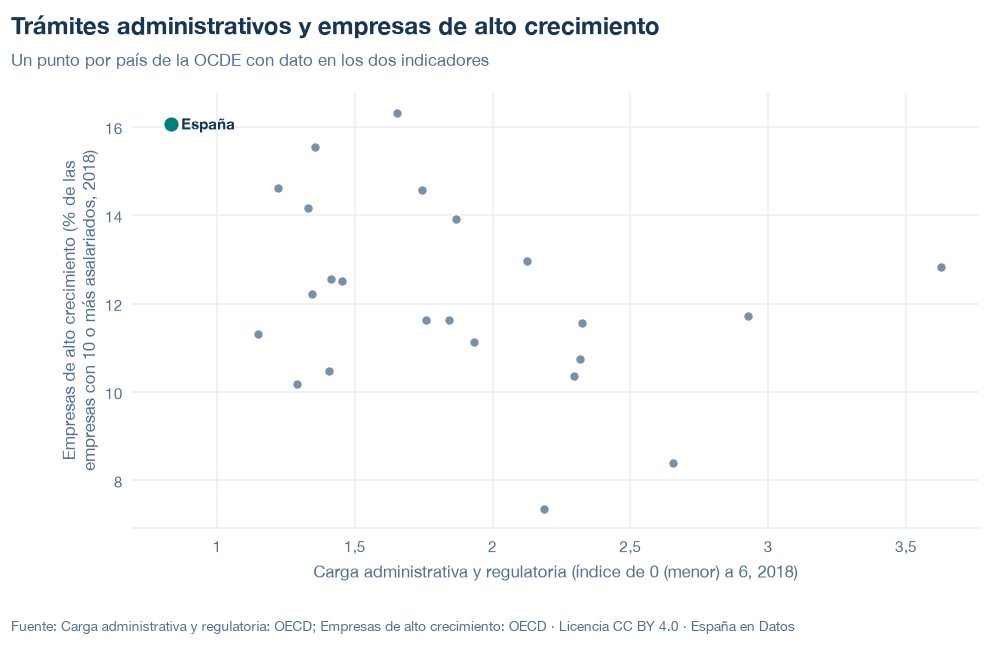

In [ ]:
datos = construir_dispersion_data(
    x, y, fuentes, id=GRAFICA_ID, universo=UNIVERSO, eje_x=EJE_X, eje_y=EJE_Y, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, anios=ANIOS,
)
fig = estilos.figura(datos, titulo=TITULO)
estilos.mostrar(fig)
print(pd.DataFrame(datos["puntos"]).to_string(index=False))

## 5. Exportación

Escribe `data/<id>.json` (validado contra el esquema) y `data/<id>.csv`, el mismo CSV que se descarga en la web (`codigo;pais;anio;eje_x;eje_y`).

In [ ]:
salida = Path(DIR_SALIDA) if DIR_SALIDA else RAIZ / "temas" / SLUG / "data"
ruta = write_dispersion_data(
    x, y, fuentes, id=GRAFICA_ID, universo=UNIVERSO, eje_x=EJE_X, eje_y=EJE_Y, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, anios=ANIOS,
    path=salida / f"{GRAFICA_ID}.json", csv_formato=CSV_FORMATO, csv_decimales=CSV_DECIMALES,
)
print(f"escrito: data/{ruta.name} y data/{ruta.stem}.csv")  # sin rutas locales en las salidas publicadas

## 6. Fuentes, notas y licencia

- OCDE, regulación de los mercados de productos: `OECD.ECO.GCRD,DSD_PMR@DF_PMR,1.3` (`ADREG_BURDEN`, `ADBURDEN`).
- OCDE, demografía empresarial: `OECD.SDD.TPS,DSD_SDBSBD_ISIC4@DF_BD_EMP_HG,1.0` y `DF_BD_EMP_B_D` (natalidad, solo notas).
- Eurostat, `bd_hgnace_r` (contraste de España).

La fecha de consulta de cada eje está en `fuentes` del JSON; las notas incluyen los países sin dato y la advertencia de que la relación no muestra causa.

**Licencia:** datos, gráficos y textos CC BY 4.0; código MIT. Cita a España en Datos.